In [1]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


(55000, 28, 28, 1) (5000, 28, 28, 1) (10000, 28, 28, 1)


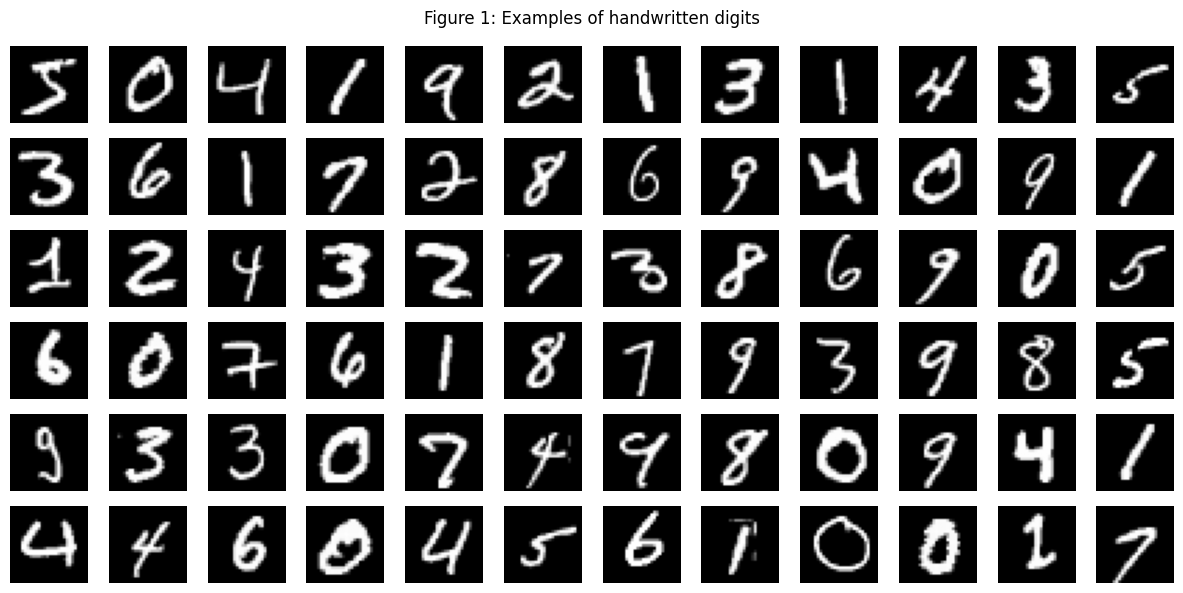

In [2]:
(x_all, y_all), (x_test, y_test) = keras.datasets.mnist.load_data()

# 60000 -> 55000 train + 5000 validation
x_train, y_train = x_all[:55000], y_all[:55000]
x_val,   y_val   = x_all[55000:], y_all[55000:]

def prep(x):
    return (x.astype("float32") / 255.0)[..., np.newaxis]   # (N,28,28,1), 值域 [0,1]

x_train, x_val, x_test = prep(x_train), prep(x_val), prep(x_test)
print(x_train.shape, x_val.shape, x_test.shape)

# Fig.1
fig, axes = plt.subplots(6, 12, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train[i, :, :, 0], cmap="gray"); ax.axis("off")
plt.suptitle("Figure 1: Examples of handwritten digits"); plt.tight_layout(); plt.show()

In [3]:
def build_cnn(filter_size=5, stride=1, alpha=0.0, dropout=0.2, c1=8, c2=16, dense_units=128, padding="valid"):
    reg  = regularizers.l2(alpha) if alpha > 0 else None
    init = keras.initializers.VarianceScaling()
    inp = keras.Input(shape=(28, 28, 1))
    x = layers.Conv2D(c1, filter_size, strides=stride, padding=padding, activation="relu",
                      kernel_initializer=init, kernel_regularizer=reg, name="conv1")(inp)
    x = layers.MaxPooling2D(2, name="pool1")(x)
    x = layers.Conv2D(c2, filter_size, strides=stride, padding=padding, activation="relu",
                      kernel_initializer=init, kernel_regularizer=reg, name="conv2")(x)
    x = layers.MaxPooling2D(2, name="pool2")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(dense_units, activation="relu", kernel_regularizer=reg, name="dense1")(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    out = layers.Dense(10, activation="softmax", kernel_initializer=init,
                       kernel_regularizer=reg, name="output")(x)
    return keras.Model(inp, out)

def compile_model(model, lr=1e-3):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.SparseCategoricalCrossentropy(name="ce")])
    return model

class TestEval(keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.acc = []
    def on_epoch_end(self, epoch, logs=None):
        r = self.model.evaluate(x_test, y_test, verbose=0, return_dict=True)
        self.acc.append(r["accuracy"])

def fit_model(filter_size=5, stride=1, alpha=0.0, dropout=0.2, epochs=20, batch_size=128,
              seed=SEED, verbose=0, **kw):
    set_seed(seed)
    model = compile_model(build_cnn(filter_size, stride, alpha, dropout, **kw))
    te = TestEval(); t0 = time.time()
    h = model.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
                  validation_data=(x_val, y_val), callbacks=[te], verbose=verbose)
    hist = dict(h.history); hist["test_acc"] = te.acc; hist["time"] = time.time() - t0
    return model, hist

build_cnn().summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 24, 24, 8)      │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 12, 12, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 8, 8, 16)       │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,610 (146.91 KB)

 Trainable params: 37,610 (146.91 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
BASE_K, BASE_S, BASE_EPOCHS = 5, 1, 10      # 與參考Notebook相同
base_model, base_hist = fit_model(BASE_K, BASE_S, epochs=BASE_EPOCHS, verbose=1)
print("Final test acc:", base_hist["test_acc"][-1])

Epoch 1/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8976 - ce: 0.3356 - loss: 0.3356 - val_accuracy: 0.9772 - val_ce: 0.0815 - val_loss: 0.0815
Epoch 2/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9717 - ce: 0.0922 - loss: 0.0922 - val_accuracy: 0.9842 - val_ce: 0.0541 - val_loss: 0.0541
Epoch 3/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9798 - ce: 0.0679 - loss: 0.0679 - val_accuracy: 0.9886 - val_ce: 0.0445 - val_loss: 0.0445
Epoch 4/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9826 - ce: 0.0554 - loss: 0.0554 - val_accuracy: 0.9894 - val_ce: 0.0406 - val_loss: 0.0406
Epoch 5/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9853 - ce: 0.0463 - loss: 0.0463 - val_accuracy: 0.9900 - val_ce: 0.0384 - val_loss: 0.0384
Epoch 6/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9874 - ce: 0.0407 - loss: 0.0407 - val_accuracy: 0.9906 - val_ce: 0.0378 - val_loss: 0.0378
Epoch 7/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step 

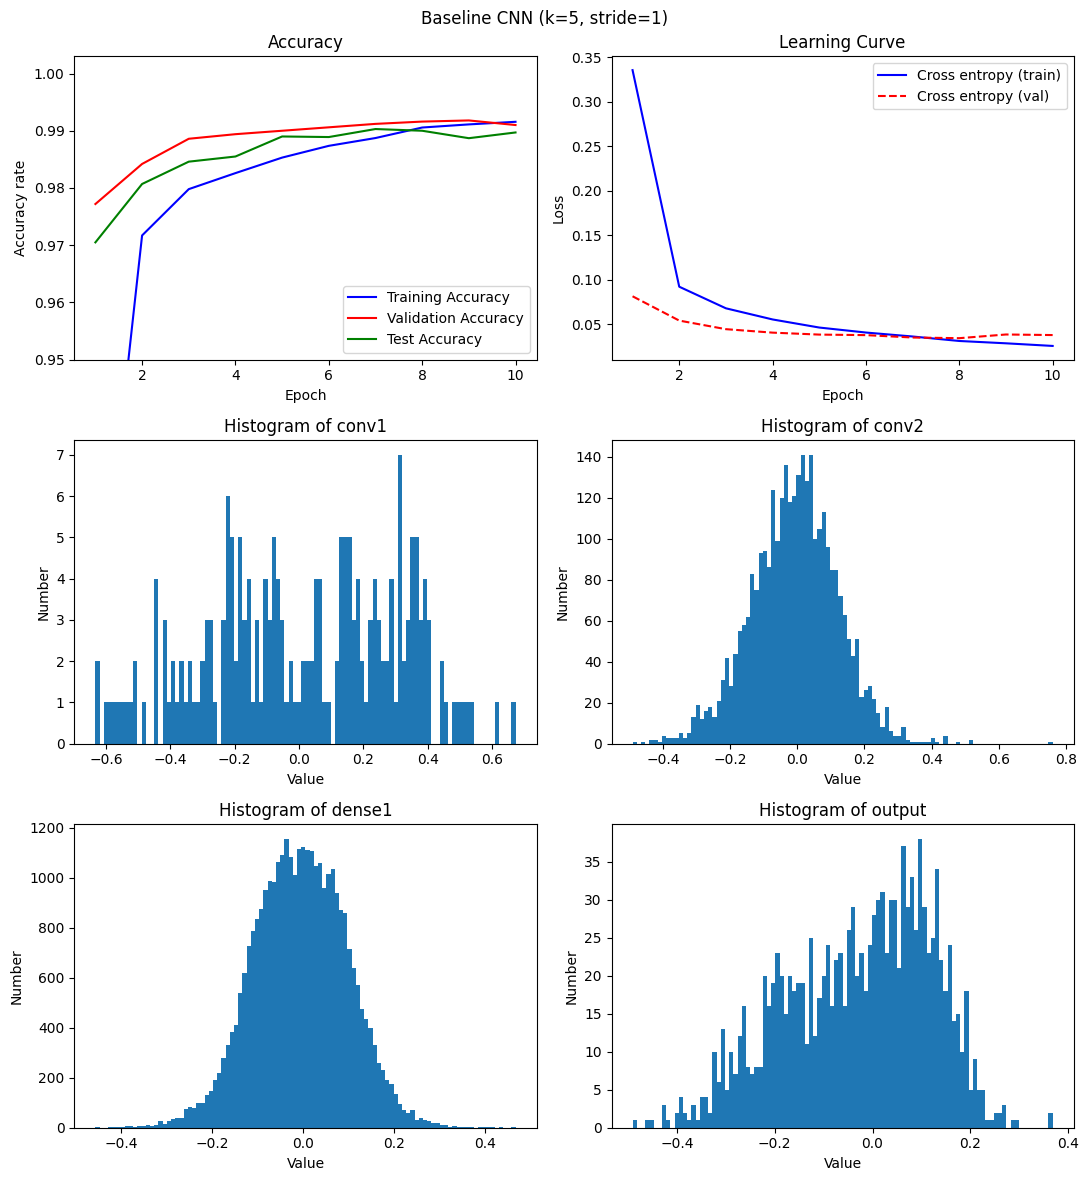

In [5]:
LAYERS = ["conv1", "conv2", "dense1", "output"]

def get_params(model, kind="kernel"):
    out = {}
    for n in LAYERS:
        w, b = model.get_layer(n).get_weights()
        out[n] = (w if kind == "kernel" else b).ravel()
    return out

def plot_results(hist, model, title="", xlim=None, bins=100):
    ep = np.arange(1, len(hist["accuracy"]) + 1)
    fig, axes = plt.subplots(3, 2, figsize=(11, 12))
    ax = axes[0, 0]
    ax.plot(ep, hist["accuracy"], "b", label="Training Accuracy")
    ax.plot(ep, hist["val_accuracy"], "r", label="Validation Accuracy")
    ax.plot(ep, hist["test_acc"], "g", label="Test Accuracy")
    ax.set_title("Accuracy"); ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy rate")
    ax.set_ylim(0.95, 1.003); ax.legend(loc="lower right")
    ax = axes[0, 1]
    ax.plot(ep, hist["ce"], "b", label="Cross entropy (train)")
    ax.plot(ep, hist["val_ce"], "r--", label="Cross entropy (val)")
    ax.set_title("Learning Curve"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.legend()
    ws = get_params(model, "kernel")
    for ax, n in zip(axes[1:].ravel(), LAYERS):
        ax.hist(ws[n], bins=bins, range=xlim)
        ax.set_title(f"Histogram of {n}"); ax.set_xlabel("Value"); ax.set_ylabel("Number")
    plt.suptitle(title); plt.tight_layout(); plt.show()

def plot_bias_hist(model, bins=40):
    bs = get_params(model, "bias")
    fig, axes = plt.subplots(1, 4, figsize=(16, 3))
    for ax, n in zip(axes, LAYERS):
        ax.hist(bs[n], bins=bins); ax.set_title(f"Bias of {n}"); ax.set_xlabel("Value")
    plt.tight_layout(); plt.show()

plot_results(base_hist, base_model, title=f"Baseline CNN (k={BASE_K}, stride={BASE_S})")

# 參考Notebook存檔
base_model.save("digits_recognition_cnn.keras")

In [6]:
def receptive_field(cfg):
    rf, jump = 1, 1
    for k, s in cfg:
        rf += (k - 1) * jump; jump *= s
    return rf

rows = []
for s in [1, 2]:
    for k in [3, 5, 7]:
        runs = []
        for sd in (0, 1, 2):
            m, h = fit_model(k, s, epochs=8, seed=sd, padding="same")
            runs.append((h["accuracy"][-1], h["val_accuracy"][-1], h["test_acc"][-1], h["time"]))
        a = np.array(runs)
        rows.append(dict(filter=k, stride=s, params=m.count_params(),
                         RF=receptive_field([(k, s), (2, 2), (k, s), (2, 2)]),
                         train=a[:, 0].mean(), val=a[:, 1].mean(), val_std=a[:, 1].std(),
                         test=a[:, 2].mean(), test_std=a[:, 2].std(),
                         gap=(a[:, 0] - a[:, 1]).mean(), time_s=a[:, 3].mean()))
        print("done", k, s)
df = pd.DataFrame(rows)
df.round(4)

done 3 1
done 5 1
done 7 1
done 3 2
done 5 2
done 7 2


,filter,stride,params,RF,train,val,val_std,test,test_std,gap,time_s
0,3,1,103018,10,0.9907,0.9909,0.0009,0.9889,0.0008,-0.0002,26.8467
1,5,1,105194,16,0.9918,0.9903,0.0008,0.9911,0.0009,0.0014,31.2928
2,7,1,108458,22,0.9925,0.9915,0.0007,0.9911,0.0005,0.0009,33.5814
3,3,2,10858,21,0.9673,0.9783,0.0003,0.9728,0.0009,-0.0110,16.3308
4,5,2,13034,31,0.9783,0.9823,0.0011,0.9800,0.0006,-0.0041,16.3968
5,7,2,16298,41,0.9827,0.9835,0.0014,0.9835,0.0015,-0.0009,17.4155


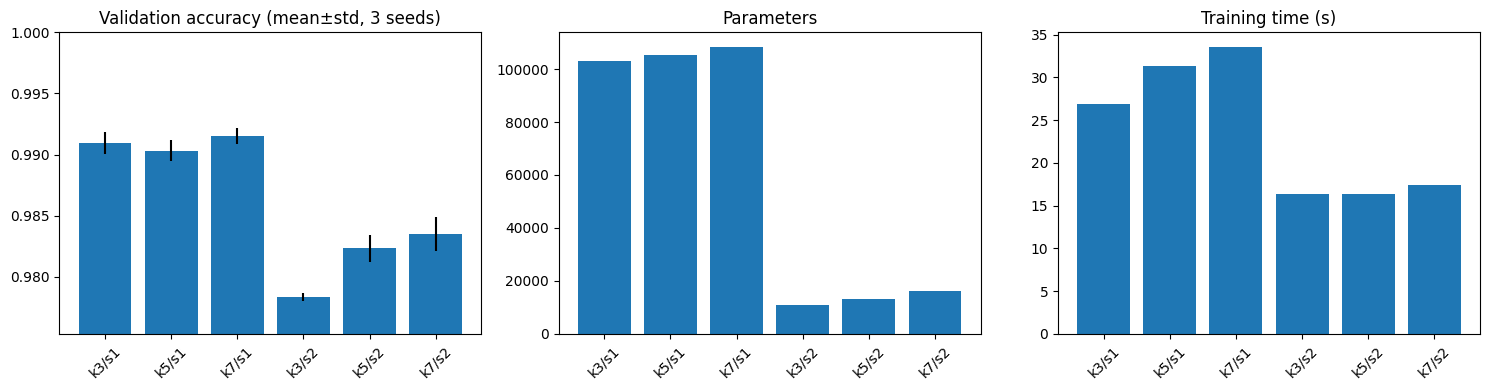

以validation accuracy選出的最佳組合: filter=7, stride=1


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
lab = [f"k{r.filter}/s{r.stride}" for r in df.itertuples()]
axes[0].bar(lab, df["val"], yerr=df["val_std"]); axes[0].set_ylim(df["val"].min() - 0.003, 1)
axes[0].set_title("Validation accuracy (mean±std, 3 seeds)")
axes[1].bar(lab, df["params"]); axes[1].set_title("Parameters")
axes[2].bar(lab, df["time_s"]); axes[2].set_title("Training time (s)")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

best = df.loc[df["val"].idxmax()]
print(f"以validation accuracy選出的最佳組合: filter={int(best['filter'])}, stride={int(best['stride'])}")

Test accuracy: 0.9897 | misclassified: 103


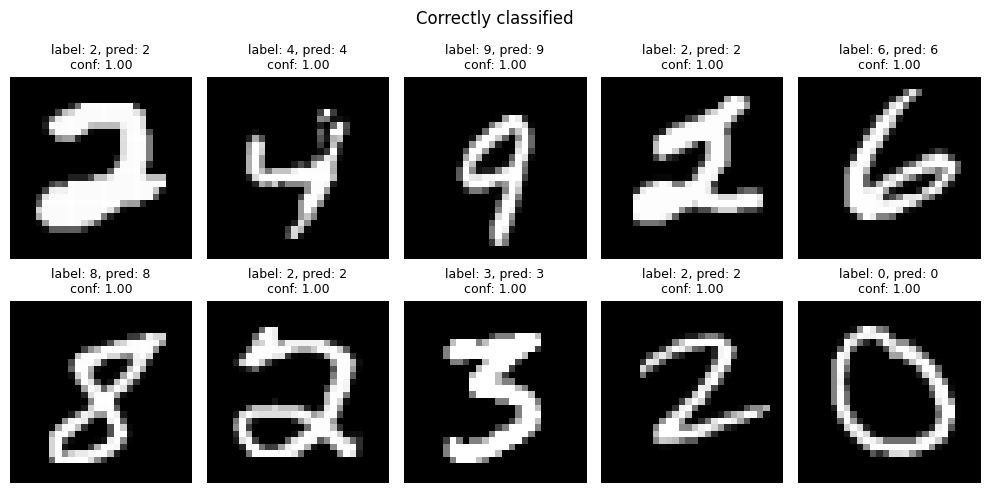

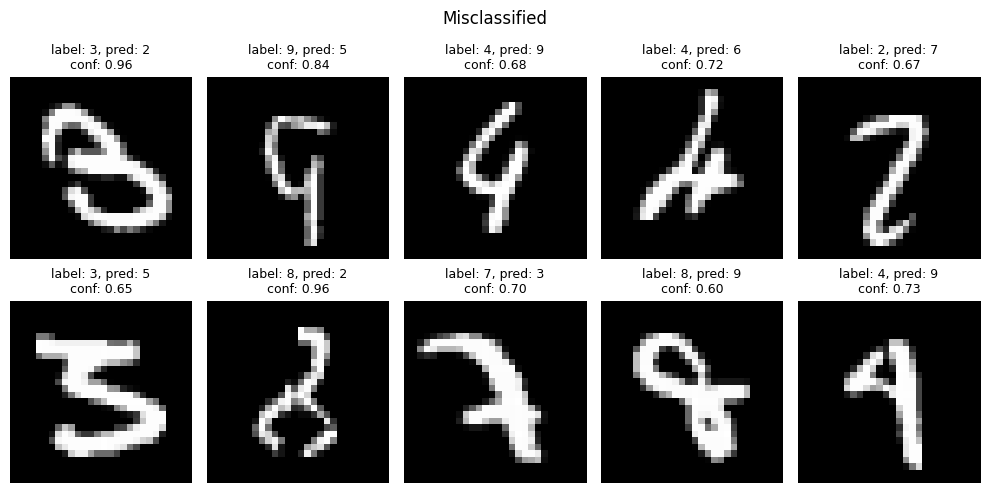

In [8]:
probs = base_model.predict(x_test, verbose=0)
pred = probs.argmax(1)
correct_idx = np.where(pred == y_test)[0]
wrong_idx = np.where(pred != y_test)[0]
print(f"Test accuracy: {len(correct_idx)/len(y_test):.4f} | misclassified: {len(wrong_idx)}")

def show_samples(idxs, title, n=10):
    fig, axes = plt.subplots(2, n // 2, figsize=(2 * n // 2, 5.2))
    for ax, i in zip(axes.ravel(), idxs[:n]):
        ax.imshow(x_test[i, :, :, 0], cmap="gray")
        ax.set_title(f"label: {y_test[i]}, pred: {pred[i]}\nconf: {probs[i, pred[i]]:.2f}", fontsize=9)
        ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.RandomState(0)
show_samples(rng.choice(correct_idx, 10, replace=False), "Correctly classified")
show_samples(wrong_idx, "Misclassified")

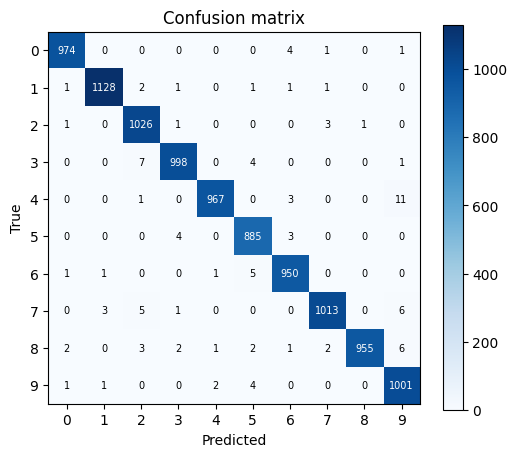

最常見的錯誤(true -> pred : 次數)
  4 -> 9 : 11
  3 -> 2 : 7
  8 -> 9 : 6
  7 -> 9 : 6
  7 -> 2 : 5
  6 -> 5 : 5
  9 -> 5 : 4
  5 -> 3 : 4


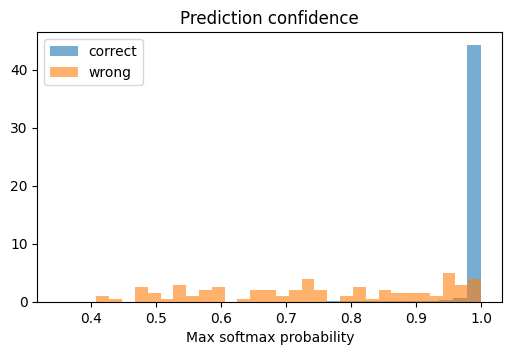

In [9]:
cm = tf.math.confusion_matrix(y_test, pred, num_classes=10).numpy()
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(10)); plt.yticks(range(10)); plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion matrix"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j] > 0], reverse=True)[:8]
print("最常見的錯誤(true -> pred : 次數)")
for c, i, j in pairs: print(f"  {i} -> {j} : {c}")

plt.figure(figsize=(6, 3.5))
plt.hist(probs[correct_idx].max(1), bins=30, alpha=.6, density=True, label="correct")
plt.hist(probs[wrong_idx].max(1), bins=30, alpha=.6, density=True, label="wrong")
plt.xlabel("Max softmax probability"); plt.legend(); plt.title("Prediction confidence"); plt.show()

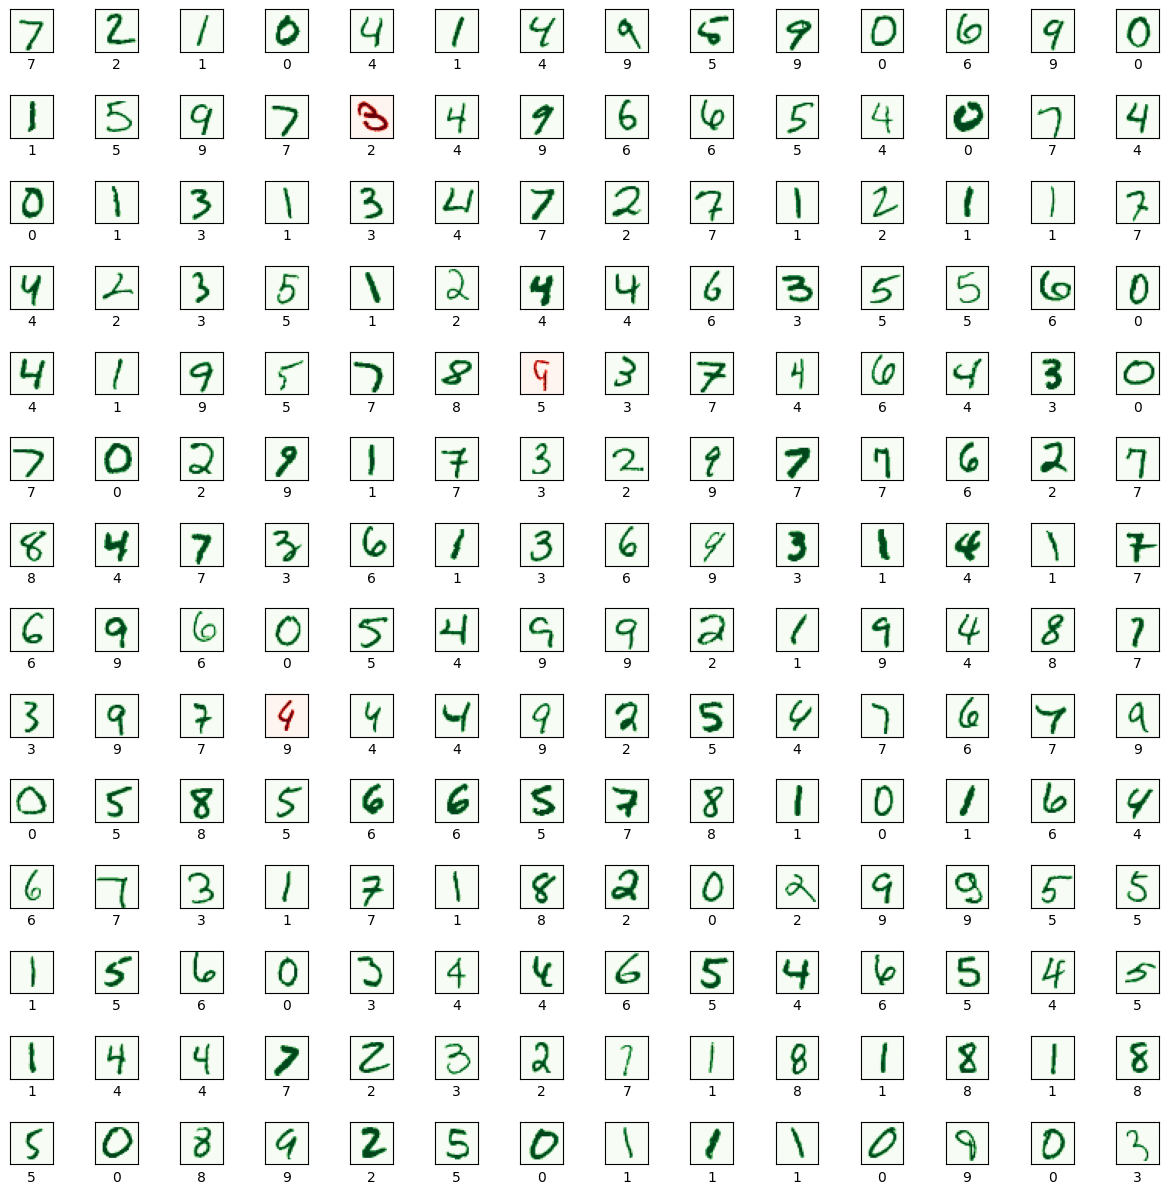

In [10]:
# 參考Notebook:前196張測試圖,綠色=預測正確、紅色=預測錯誤,下方數字為預測值
n_show = 196; cells_n = int(np.ceil(np.sqrt(n_show)))
plt.figure(figsize=(15, 15))
for i in range(n_show):
    plt.subplot(cells_n, cells_n, i + 1)
    plt.imshow(x_test[i, :, :, 0], cmap="Greens" if pred[i] == y_test[i] else "Reds")
    plt.xticks([]); plt.yticks([]); plt.xlabel(pred[i])
plt.subplots_adjust(hspace=1, wspace=0.5); plt.show()

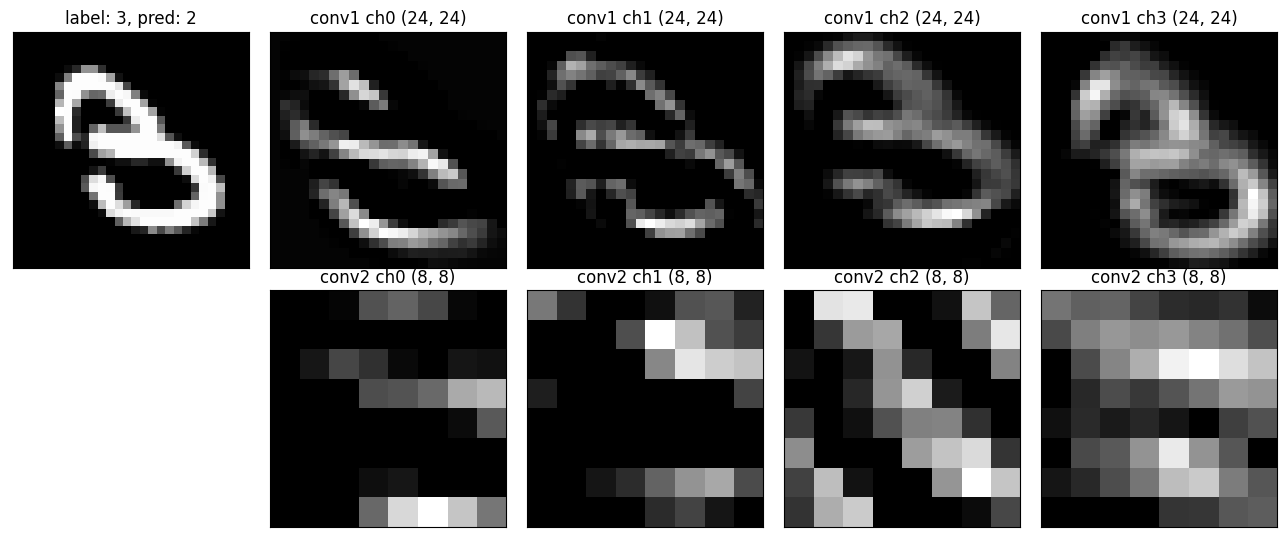

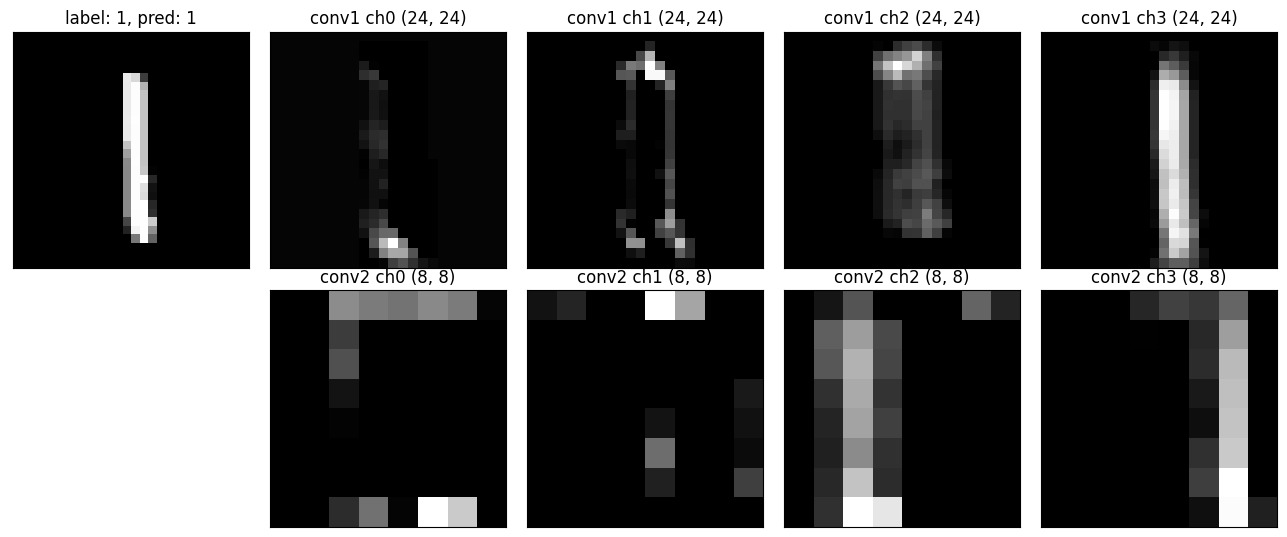

In [11]:
feat_model = keras.Model(base_model.inputs,
                         [base_model.get_layer("conv1").output, base_model.get_layer("conv2").output])

def show_feature_maps(i, n_ch=4):
    f1, f2 = [f[0] for f in feat_model.predict(x_test[i:i+1], verbose=0)]
    n_ch = min(n_ch, f1.shape[-1], f2.shape[-1])
    fig, axes = plt.subplots(2, n_ch + 1, figsize=(2.6 * (n_ch + 1), 5.4))
    axes[0, 0].imshow(x_test[i, :, :, 0], cmap="gray"); axes[0, 0].set_title(f"label: {y_test[i]}, pred: {pred[i]}")
    axes[1, 0].axis("off")
    for c in range(n_ch):
        axes[0, c + 1].imshow(f1[:, :, c], cmap="gray"); axes[0, c + 1].set_title(f"conv1 ch{c} {f1.shape[:2]}")
        axes[1, c + 1].imshow(f2[:, :, c], cmap="gray"); axes[1, c + 1].set_title(f"conv2 ch{c} {f2.shape[:2]}")
    for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.show()

show_feature_maps(wrong_idx[0])
show_feature_maps(rng.choice(correct_idx))

In [12]:
alphas = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
l2 = {}
for a in alphas:
    m, h = fit_model(BASE_K, BASE_S, alpha=a, epochs=BASE_EPOCHS)
    l2[a] = (m, h)
    w = np.concatenate(list(get_params(m, "kernel").values()))
    print(f"alpha={a:<7} | train={h['accuracy'][-1]:.4f} | val={h['val_accuracy'][-1]:.4f} | "
          f"test={h['test_acc'][-1]:.4f} | gap={h['accuracy'][-1]-h['test_acc'][-1]:+.4f} | "
          f"|w|<0.01: {np.mean(np.abs(w)<0.01):.3f} | mean|w|={np.mean(np.abs(w)):.4f}")

alpha=0.0     | train=0.9916 | val=0.9910 | test=0.9897 | gap=+0.0019 | |w|<0.01: 0.071 | mean|w|=0.0863
alpha=0.0001  | train=0.9907 | val=0.9906 | test=0.9882 | gap=+0.0025 | |w|<0.01: 0.242 | mean|w|=0.0563
alpha=0.001   | train=0.9843 | val=0.9896 | test=0.9864 | gap=-0.0021 | |w|<0.01: 0.376 | mean|w|=0.0266
alpha=0.01    | train=0.9591 | val=0.9684 | test=0.9663 | gap=-0.0072 | |w|<0.01: 0.588 | mean|w|=0.0138
alpha=0.1     | train=0.8301 | val=0.8824 | test=0.8581 | gap=-0.0280 | |w|<0.01: 0.860 | mean|w|=0.0051


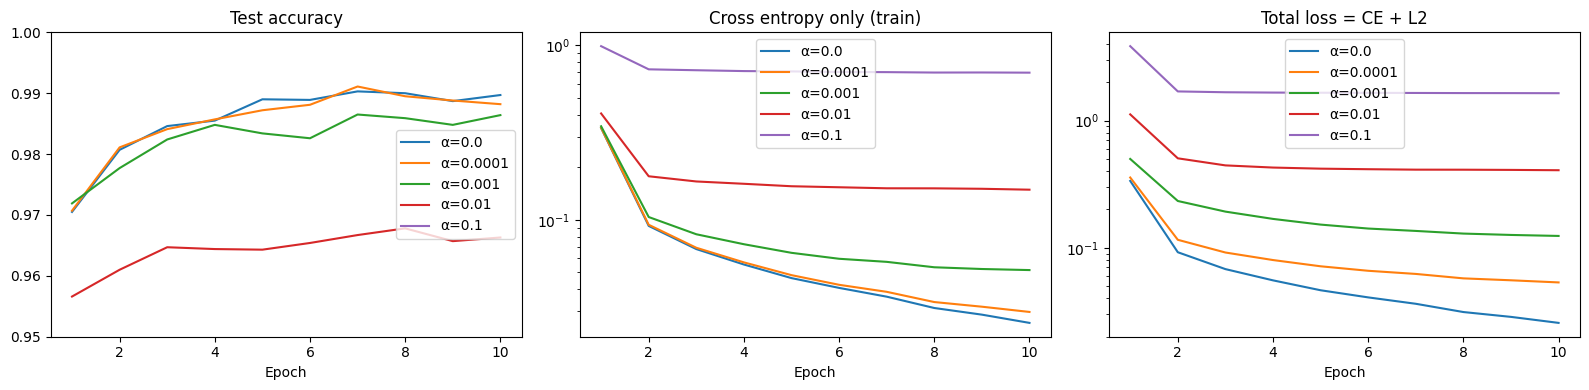

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for a, (m, h) in l2.items():
    ep = np.arange(1, len(h["ce"]) + 1)
    axes[0].plot(ep, h["test_acc"], label=f"α={a}")
    axes[1].plot(ep, h["ce"], label=f"α={a}")
    axes[2].plot(ep, h["loss"], label=f"α={a}")
axes[0].set_ylim(0.95, 1.0); axes[0].set_title("Test accuracy")
axes[1].set_yscale("log"); axes[1].set_title("Cross entropy only (train)")
axes[2].set_yscale("log"); axes[2].set_title("Total loss = CE + L2")
for ax in axes: ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

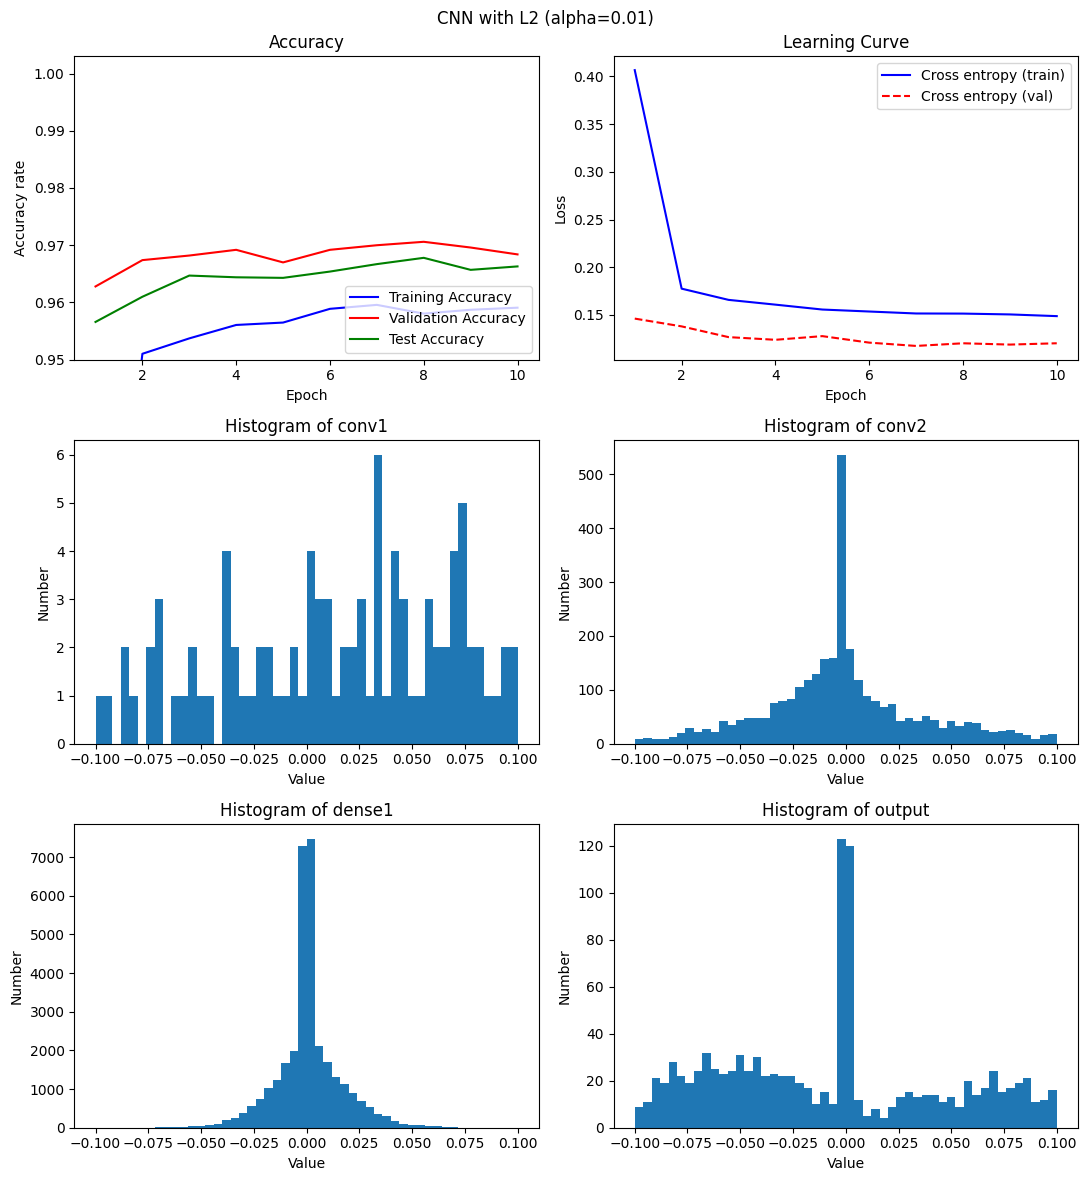

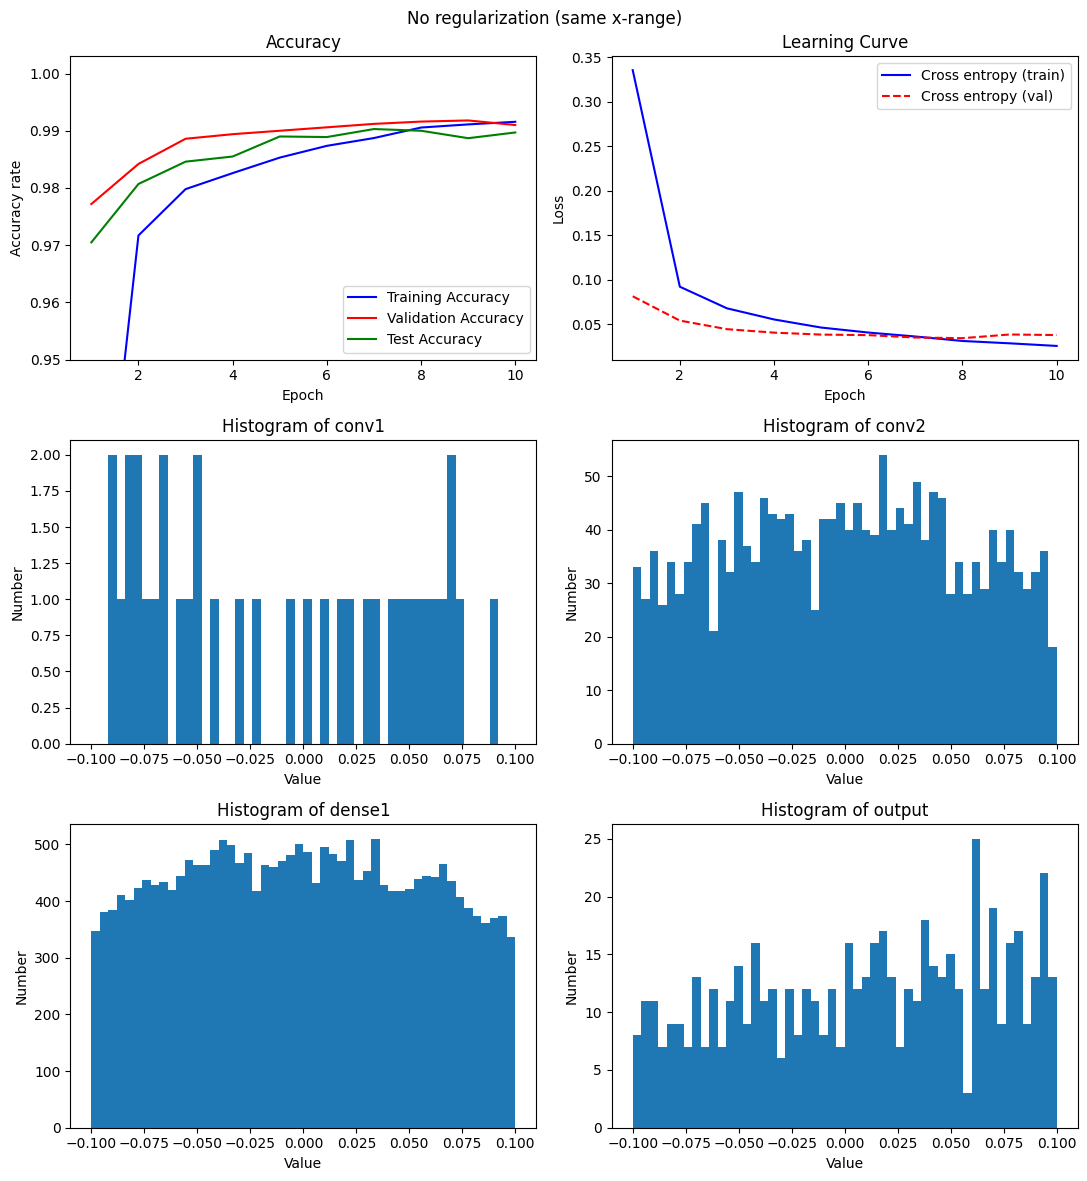

In [14]:
ALPHA_SHOW = 1e-2
m, h = l2[ALPHA_SHOW]
plot_results(h, m, title=f"CNN with L2 (alpha={ALPHA_SHOW})", xlim=(-0.1, 0.1), bins=50)
plot_results(l2[0.0][1], l2[0.0][0], title="No regularization (same x-range)", xlim=(-0.1, 0.1), bins=50)